# Where do the answers sit in a CUAD contract?

One question: **if we only send the first N characters of a contract to the model, how many gold answers are still in view?**
That is what decides the context length.

Data: the CUAD records in `data/unified/dev.jsonl`. Each non-null field has `gold_evidence.spans`, the character
offsets of the answer inside the contract text (looked up in `data/raw/cuad/CUADv1.json` by title).

In [1]:
import json, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/unified/dev.jsonl").exists())
DATA = ROOT / "data"

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "axes.labelsize": 9, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "text.color": INK, "font.size": 9.5,
    "xtick.major.size": 0, "ytick.major.size": 0,
})
pd.set_option("display.width", 200)

In [2]:
records = [json.loads(l) for l in (DATA / "unified/dev.jsonl").open(encoding="utf-8")]
cuad = [r for r in records if r["source_dataset"] == "cuad"]
raw = json.loads((DATA / "raw/cuad/CUADv1.json").read_text(encoding="utf-8"))["data"]
context = {d["title"]: "\n".join(p["context"] for p in d["paragraphs"]) for d in raw}

# One row per gold span: where it starts and ends, in characters from the start of the contract.
rows = []
for r in cuad:
    n = len(context[r["doc_id"].split(":", 1)[1]])
    for field, ev in r["gold_evidence"].items():
        for s in ev["spans"]:
            rows.append({"doc_id": r["doc_id"], "field": field, "start": s["start"], "end": s["end"], "doc_chars": n})
spans = pd.DataFrame(rows)
doc_chars = spans.groupby("doc_id").doc_chars.first()

# One row per non-null field: the field is only fully in view once its LAST span has ended.
fields = spans.groupby(["doc_id", "field"]).agg(first_start=("start", "min"), last_end=("end", "max")).reset_index()

print(f"{len(cuad)} contracts, {len(fields):,} non-null fields, {len(spans):,} gold spans")
print(f"contract length (chars): median {doc_chars.median():,.0f}, p90 {doc_chars.quantile(.9):,.0f}, max {doc_chars.max():,}")
print(f"span end position (chars): median {spans.end.median():,.0f}, p90 {spans.end.quantile(.9):,.0f}, p99 {spans.end.quantile(.99):,.0f}")

381 contracts, 5,014 non-null fields, 10,374 gold spans
contract length (chars): median 32,680, p90 134,179, max 338,211
span end position (chars): median 17,932, p90 105,580, p99 228,629


## Where in the contract do answers occur, by quarter?

Each contract is cut into four equal sections by length: **0-25%, 25-50%, 50-75%, 75-100%**.
A gold span is assigned to the section its first character falls in.

The sections are relative, so their size in tokens depends on the contract. The second table gives the token
range each section covers for a short, a typical and a long contract (tokens estimated at 4 characters each).

In [7]:
QUARTERS = ["0-25%", "25-50%", "50-75%", "75-100%"]
spans["rel_start"] = spans.start / spans.doc_chars
spans["quarter"] = pd.Categorical.from_codes(np.minimum((spans.rel_start * 4).astype(int), 3), QUARTERS, ordered=True)

by_q = spans.groupby("quarter", observed=False)
n_fields = spans.groupby(["doc_id", "field"]).ngroups
where = pd.DataFrame({
    "gold spans": by_q.size(),
    "share of spans": by_q.size() / len(spans),
    "share of answer text (chars)": by_q.apply(lambda d: (d.end - d.start).sum(), include_groups=False) / (spans.end - spans.start).sum(),
    "non-null fields with a span here": by_q.apply(lambda d: d.groupby(["doc_id", "field"]).ngroups, include_groups=False) / n_fields,
})
show = where.copy()
for c in show.columns[1:]:
    show[c] = show[c].map("{:.1%}".format)
display(show)
print("('fields with a span here' adds up to more than 100% because multi-span fields can touch several sections)")

# Token range of each section, for contracts of different lengths (4 chars ~ 1 token).
doc_tokens = doc_chars / 4
sizes = {"short contract (p10)": doc_tokens.quantile(.10), "typical contract (median)": doc_tokens.median(),
         "long contract (p90)": doc_tokens.quantile(.90), "longest contract": doc_tokens.max()}
ranges = pd.DataFrame({f"{name}, {total:,.0f} tokens": [f"{total * i / 4:,.0f} - {total * (i + 1) / 4:,.0f}" for i in range(4)]
                       for name, total in sizes.items()}, index=QUARTERS)
ranges.index.name = "section"
sec = doc_tokens / 4
ranges["tokens per section (median, p10-p90)"] = f"{sec.median():,.0f}  ({sec.quantile(.1):,.0f} - {sec.quantile(.9):,.0f})"
ranges

,gold spans,share of spans,share of answer text (chars),non-null fields with a span here
quarter,,,,
0-25%,4267,41.1%,23.1%,45.3%
25-50%,2199,21.2%,29.4%,23.2%
50-75%,2133,20.6%,27.3%,24.8%
75-100%,1775,17.1%,20.2%,22.5%


('fields with a span here' adds up to more than 100% because multi-span fields can touch several sections)


,"short contract (p10), 1,585 tokens","typical contract (median), 8,170 tokens","long contract (p90), 33,545 tokens","longest contract, 84,553 tokens","tokens per section (median, p10-p90)"
section,,,,,
0-25%,0 - 396,"0 - 2,042","0 - 8,386","0 - 21,138","2,042 (396 - 8,386)"
25-50%,396 - 793,"2,042 - 4,085","8,386 - 16,772","21,138 - 42,276","2,042 (396 - 8,386)"
50-75%,"793 - 1,189","4,085 - 6,128","16,772 - 25,159","42,276 - 63,415","2,042 (396 - 8,386)"
75-100%,"1,189 - 1,585","6,128 - 8,170","25,159 - 33,545","63,415 - 84,553","2,042 (396 - 8,386)"


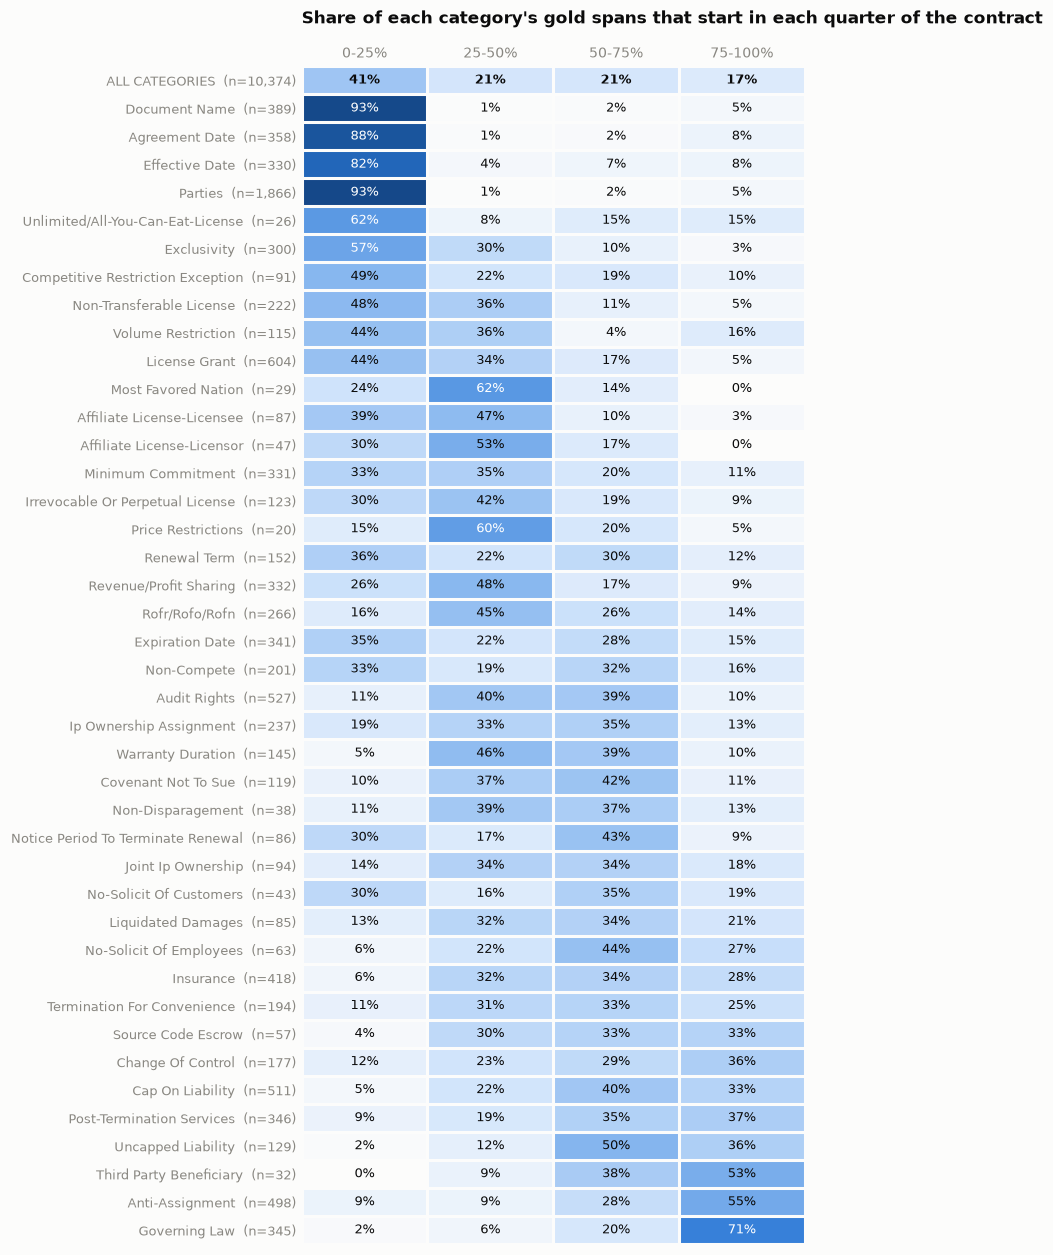

Categories with most spans in the second half: Governing Law (92%), Third Party Beneficiary (91%), Uncapped Liability (86%), Anti-Assignment (83%), Cap On Liability (74%), No-Solicit Of Employees (71%)
Categories with most spans in the first quarter: Parties (93%), Document Name (93%), Agreement Date (88%), Effective Date (82%), Unlimited/All-You-Can-Eat-License (62%), Exclusivity (57%)


In [8]:
from matplotlib.colors import LinearSegmentedColormap
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#0d366b"])

cat_q = pd.crosstab(spans.field, spans.quarter, normalize="index").reindex(columns=QUARTERS, fill_value=0)
cat_q = cat_q.loc[spans.groupby("field").rel_start.median().sort_values().index]      # early categories on top
heat = pd.concat([where["share of spans"].rename("ALL CATEGORIES").to_frame().T, cat_q])
n_spans = pd.concat([pd.Series({"ALL CATEGORIES": len(spans)}), spans.groupby("field").size()])

fig, ax = plt.subplots(figsize=(7.5, 11.5))
ax.imshow(heat.values, aspect="auto", cmap=SEQ, vmin=0, vmax=1)
for i in range(heat.shape[0]):
    for j in range(4):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8.5, color="#ffffff" if v > 0.55 else INK,
                fontweight="bold" if i == 0 else "normal")
ax.set_xticks(range(4)); ax.set_xticklabels(QUARTERS, fontsize=9); ax.xaxis.tick_top()
ax.set_yticks(range(len(heat))); ax.set_yticklabels([f"{k}  (n={n_spans[k]:,})" for k in heat.index])
ax.set_xticks(np.arange(-.5, 4), minor=True); ax.set_yticks(np.arange(-.5, len(heat)), minor=True)
ax.grid(False); ax.grid(which="minor", color="#fcfcfb", linewidth=2); ax.tick_params(which="minor", length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_title("Share of each category's gold spans that start in each quarter of the contract", pad=28)
plt.tight_layout(); plt.show()

late = cat_q[["50-75%", "75-100%"]].sum(axis=1).sort_values(ascending=False)
print("Categories with most spans in the second half: " + ", ".join(f"{k} ({v:.0%})" for k, v in late.head(6).items()))
print("Categories with most spans in the first quarter: " + ", ".join(f"{k} ({v:.0%})" for k, v in cat_q["0-25%"].sort_values(ascending=False).head(6).items()))